# Text Pre-processing

Arya Bima Nugraha (238)

M. Haekal Fallah Ar-Rahman (061)

## 1. Install & import library

In [7]:
!pip install demoji wordcloud -q

In [8]:
import pandas as pd
import re
import nltk
import demoji
from wordcloud import WordCloud
import matplotlib.pyplot as plt

nltk.download('stopwords')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 2. Data teks sumber


In [9]:
data = [
    {'video_id': 'SrvLb03AXok', 'title': 'FIRST LOVE LETTER (1991) Full Movie HD | Romantic Drama',
     'description': 'First Love Letter (1991) – Movie Details 🎬 Directed by a renowned filmmaker, this romantic drama follows a heartfelt story ❤️'},
    {'video_id': 'bDe5W2I8Sgc', 'title': 'The Love Letter | Best Friend, Secret Crush, Wedding',
     'description': 'A journalist anonymously confesses her secret feelings in a love letter sent to her best friend 💌'},
    {'video_id': 'ffuFHYh6TWs', 'title': 'Love Letter (1995) PT-BR',
     'description': 'Data de lançamento: 25 de março de 1995 (Japão) 🇧🇷'},
    {'video_id': 'WsKyc8gJW1k', 'title': 'LOVE LETTER',
     'description': 'ANOTHER RARE TIME TRAVEL MOVIE (SORT OF) NOT AVAILABLE anywhere else online 😱'},
    {'video_id': 'P6JAtpSC0EA', 'title': 'Love Letter (1995) OFFICIAL TRAILER [HD]',
     'description': 'Directed by Shunji Iwai. With Miho Nakayama, Etsushi Toyokawa 🎥'},
    {'video_id': 'sV9JaCWTDgE', 'title': 'FIRST LOVE LETTER (1991) | Superhit Hindi Romantic Movie',
     'description': 'FIRST LOVE LETTER (1991) | Superhit Hindi Romantic Movie, full drama and emotions 😢'},
    {'video_id': 'V_tCZB4YRbE', 'title': 'Love Letter (1995) - mountain scene',
     'description': 'Director: Shunji Iwai Writer: Shunji Iwai Starring the iconic mountain scene ⛰️'},
    {'video_id': 'tvneMVSrvbU', 'title': 'Love Letter (1995) | 4K Restoration Trailer',
     'description': 'In Theaters June 5. Hiroko is still in the depths of grief years after her fiancé died in a climbing accident 😢💔'},
]

df_text = pd.DataFrame(data)

## 3. Fungsi-fungsi pre-processing

In [10]:
def remove_rls(text):
    text = re.sub(r'https?\/\/\S+', '', str(text))
    text = re.sub(r'http\S+', '', str(text))
    text = re.sub(r'www\S+', '', str(text))
    text = re.sub(r'\S+@\S+', '', str(text))
    return text

def remove_punctuation(text):
    text = re.sub(r'[!"#$%&\'()*+,\-./:;<=>?@\[\]^_`{|}~\u2013\u2014]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def remove_emoji(text):
    return demoji.replace(text, repl='')

## 4. Menjalankan tahapan pre-processing

In [11]:
df_text['lower_case'] = df_text['description'].str.lower()
df_text[['description', 'lower_case']]

,description,lower_case
0,First Love Letter (1991) – Movie Details 🎬 Dir...,first love letter (1991) – movie details 🎬 dir...
1,A journalist anonymously confesses her secret ...,a journalist anonymously confesses her secret ...
2,Data de lançamento: 25 de março de 1995 (Japão...,data de lançamento: 25 de março de 1995 (japão...
3,ANOTHER RARE TIME TRAVEL MOVIE (SORT OF) NOT A...,another rare time travel movie (sort of) not a...
4,"Directed by Shunji Iwai. With Miho Nakayama, E...","directed by shunji iwai. with miho nakayama, e..."
5,FIRST LOVE LETTER (1991) | Superhit Hindi Roma...,first love letter (1991) | superhit hindi roma...
6,Director: Shunji Iwai Writer: Shunji Iwai Star...,director: shunji iwai writer: shunji iwai star...
7,In Theaters June 5. Hiroko is still in the dep...,in theaters june 5. hiroko is still in the dep...


In [12]:
df_text['rm_url'] = df_text['lower_case'].apply(remove_rls)
df_text[['lower_case', 'rm_url']]

,lower_case,rm_url
0,first love letter (1991) – movie details 🎬 dir...,first love letter (1991) – movie details 🎬 dir...
1,a journalist anonymously confesses her secret ...,a journalist anonymously confesses her secret ...
2,data de lançamento: 25 de março de 1995 (japão...,data de lançamento: 25 de março de 1995 (japão...
3,another rare time travel movie (sort of) not a...,another rare time travel movie (sort of) not a...
4,"directed by shunji iwai. with miho nakayama, e...","directed by shunji iwai. with miho nakayama, e..."
5,first love letter (1991) | superhit hindi roma...,first love letter (1991) | superhit hindi roma...
6,director: shunji iwai writer: shunji iwai star...,director: shunji iwai writer: shunji iwai star...
7,in theaters june 5. hiroko is still in the dep...,in theaters june 5. hiroko is still in the dep...


In [13]:
df_text['rm_punc'] = df_text['rm_url'].apply(remove_punctuation)
df_text[['rm_url', 'rm_punc']]

,rm_url,rm_punc
0,first love letter (1991) – movie details 🎬 dir...,first love letter 1991 movie details 🎬 directe...
1,a journalist anonymously confesses her secret ...,a journalist anonymously confesses her secret ...
2,data de lançamento: 25 de março de 1995 (japão...,data de lançamento 25 de março de 1995 japão 🇧🇷
3,another rare time travel movie (sort of) not a...,another rare time travel movie sort of not ava...
4,"directed by shunji iwai. with miho nakayama, e...",directed by shunji iwai with miho nakayama ets...
5,first love letter (1991) | superhit hindi roma...,first love letter 1991 superhit hindi romantic...
6,director: shunji iwai writer: shunji iwai star...,director shunji iwai writer shunji iwai starri...
7,in theaters june 5. hiroko is still in the dep...,in theaters june 5 hiroko is still in the dept...


In [14]:
df_text['rm_emoji'] = df_text['rm_punc'].apply(remove_emoji)
df_text[['rm_punc', 'rm_emoji']]

,rm_punc,rm_emoji
0,first love letter 1991 movie details 🎬 directe...,first love letter 1991 movie details directed...
1,a journalist anonymously confesses her secret ...,a journalist anonymously confesses her secret ...
2,data de lançamento 25 de março de 1995 japão 🇧🇷,data de lançamento 25 de março de 1995 japão
3,another rare time travel movie sort of not ava...,another rare time travel movie sort of not ava...
4,directed by shunji iwai with miho nakayama ets...,directed by shunji iwai with miho nakayama ets...
5,first love letter 1991 superhit hindi romantic...,first love letter 1991 superhit hindi romantic...
6,director shunji iwai writer shunji iwai starri...,director shunji iwai writer shunji iwai starri...
7,in theaters june 5 hiroko is still in the dept...,in theaters june 5 hiroko is still in the dept...



## 5. Stopwords

In [15]:
sw = set(stopwords.words('english'))
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [16]:
ps = PorterStemmer()

def stem_and_remove_stopwords(text):
    tokens = word_tokenize(text)
    tokens = [ps.stem(t) for t in tokens if t not in sw]
    return ' '.join(tokens)

df_text['prepro'] = df_text['rm_emoji'].apply(stem_and_remove_stopwords)
df_text[['rm_emoji', 'prepro']]

,rm_emoji,prepro
0,first love letter 1991 movie details directed...,first love letter 1991 movi detail direct reno...
1,a journalist anonymously confesses her secret ...,journalist anonym confess secret feel love let...
2,data de lançamento 25 de março de 1995 japão,data de lançamento 25 de março de 1995 japão
3,another rare time travel movie sort of not ava...,anoth rare time travel movi sort avail anywher...
4,directed by shunji iwai with miho nakayama ets...,direct shunji iwai miho nakayama etsushi toyokawa
5,first love letter 1991 superhit hindi romantic...,first love letter 1991 superhit hindi romant m...
6,director shunji iwai writer shunji iwai starri...,director shunji iwai writer shunji iwai star i...
7,in theaters june 5 hiroko is still in the dept...,theater june 5 hiroko still depth grief year f...


## 6. WordCloud

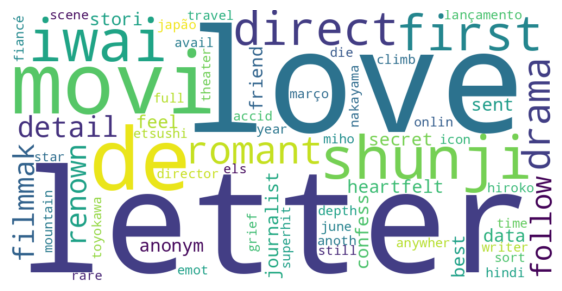

In [17]:
text = ' '.join(df_text['prepro'].dropna().astype(str))

wordcloud = WordCloud(width=1000, height=500, background_color='white', max_words=500).generate(text)

plt.figure(figsize=(7, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

## 7. Menyimpan hasil akhir

In [18]:
df_text[['video_id', 'title', 'description', 'prepro']].to_csv('exercise4_text_preprocessed.csv', index=False)
print('File berhasil disimpan sebagai exercise4_text_preprocessed.csv')
df_text[['video_id', 'title', 'prepro']]

File berhasil disimpan sebagai exercise4_text_preprocessed.csv


,video_id,title,prepro
0,SrvLb03AXok,FIRST LOVE LETTER (1991) Full Movie HD | Roman...,first love letter 1991 movi detail direct reno...
1,bDe5W2I8Sgc,"The Love Letter | Best Friend, Secret Crush, W...",journalist anonym confess secret feel love let...
2,ffuFHYh6TWs,Love Letter (1995) PT-BR,data de lançamento 25 de março de 1995 japão
3,WsKyc8gJW1k,LOVE LETTER,anoth rare time travel movi sort avail anywher...
4,P6JAtpSC0EA,Love Letter (1995) OFFICIAL TRAILER [HD],direct shunji iwai miho nakayama etsushi toyokawa
5,sV9JaCWTDgE,FIRST LOVE LETTER (1991) | Superhit Hindi Roma...,first love letter 1991 superhit hindi romant m...
6,V_tCZB4YRbE,Love Letter (1995) - mountain scene,director shunji iwai writer shunji iwai star i...
7,tvneMVSrvbU,Love Letter (1995) | 4K Restoration Trailer,theater june 5 hiroko still depth grief year f...
